# Sensitivity on hypothetical proteins (CAMI III)

Does DeepCDS recover CDS annotated as *hypothetical protein*?

Test set `CAMI_metagenome_no_cds_contigs` (sample_0): the main CAMI evaluation's contig filter, but reads
overlapping hypothetical-protein CDS are kept (they are labeled as coding in CAMI). Each labeled CDS fragment
(> 60 bp) was assigned to the annotated CDS it overlaps most (`01_classify_and_score.py`):

* **hypothetical protein**: `product=hypothetical protein` without an `ab initio prediction` inference
* **known function**: not a hypothetical protein, not an ab initio prediction, and at least one `go_function`
  (GO molecular function) term in the GFF (reference)

CDS fragments assigned to an ab initio prediction (with or without `product=hypothetical protein`) or to a named
product without a `go_function` term are not evaluated. TP = exact match (IoU = 1) as in the CAMI benchmark, or IoU >= 0.8 (setting `IOU`). Sensitivity pooled over reads; genomes with ANI >= 95% to a
train/val genome excluded (setting `EXCLUDE_OVERLAPPING_GENOMES`); SE = genome-bin
cluster bootstrap (N = 1000, seed 42).

In [1]:
import os
import sys

import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "../..")
from plot_config import MODEL_DISPLAY_NAMES

pd.set_option("display.width", 220)
RESULTS_DIR = "/tmp/nrt204/FragmentPredictor/data/processed_data/cami_hypothetical_protein_audit"
SAVE_OUTPUTS = False        # True: write the tables as CSV to RESULTS_DIR/tables/
DOMAINS = ["Bacteria", "Archaea"]   # prokaryotic genome bins; set to None for all domains
MODELS = ["deep_cds_no_errors", "deep_cds_substitution", "deep_cds_errors", "prodigal",
          "fgs_complete", "fgs_illumina_5", "fgs_illumina_10"]
CATEGORY_LABELS = {"hypothetical": "Hypothetical protein", "known_function": "Known function"}
EVALUATED = ["hypothetical", "known_function"]
N_BOOTSTRAP, SEED = 1000, 42
EXCLUDE_OVERLAPPING_GENOMES = True   # drop the 43 CAMI genomes with ANI >= 95% to a train/val genome (../cami_main_benchmark)
IOU = 1.0      # matching threshold: 1.0 (exact, as in the benchmark) or 0.8 (02_score_iou.py --iou 0.8)

counts = pd.read_csv(f"{RESULTS_DIR}/hypothetical_counts.tsv" if IOU == 1.0
                     else f"{RESULTS_DIR}/hypothetical_counts_iou{IOU:g}.tsv", sep="\t")
print(f"IoU threshold: {IOU:g}")
if DOMAINS:
    counts = counts[counts["domain"].isin(DOMAINS)]
counts = counts[counts["category"].isin(EVALUATED)]   # ab initio CDS are not evaluated
if EXCLUDE_OVERLAPPING_GENOMES:
    _ov = pd.read_csv("/tmp/nrt204/FragmentPredictor/data/processed_data/cami_main_benchmark/cami_genome_overlap.tsv", sep="	")
    _drop = set(_ov.loc[_ov["category"].isin(["identical", "same species"]), "genome_bin_id"])
    counts = counts[~counts["genome_bin_id"].isin(_drop)]
    print(f"Excluded {len(_drop)} genomes overlapping the train/val genomes")


def save(table, name):
    if SAVE_OUTPUTS:
        os.makedirs(f"{RESULTS_DIR}/tables", exist_ok=True)
        table.to_csv(f"{RESULTS_DIR}/tables/{name}.csv")

IoU threshold: 1
Excluded 43 genomes overlapping the train/val genomes


## 1. Labeled CDS fragments per annotation category

In [2]:
ref = counts[counts["model"] == MODELS[0]]
n = ref.groupby("category")["n"].sum().reindex(EVALUATED).astype(int)
summary = pd.DataFrame({"labeled CDS fragments": n, "fraction": (n / n.sum()).round(4),
                        "genome bins": ref[ref["n"] > 0].groupby("category")["genome_bin_id"].nunique()})
summary.index = [CATEGORY_LABELS[c] for c in summary.index]
display(summary)
save(summary, "category_counts")

,labeled CDS fragments,fraction,genome bins
Hypothetical protein,453124,0.0737,107
Known function,5696129,0.9263,113


## 2. Sensitivity: hypothetical proteins and CDS with known function

In [3]:
def recall_table(sub, groups, group_col="category"):
    out = {}
    for grp in groups:
        g = sub[sub[group_col] == grp]
        rng = np.random.default_rng(SEED)
        col = {}
        for model in MODELS:
            per_bin = g[g["model"] == model].groupby("genome_bin_id")[["tp", "n"]].sum()
            per_bin = per_bin[per_bin["n"] > 0]
            if per_bin.empty:
                continue
            tp, nn = per_bin["tp"].to_numpy(float), per_bin["n"].to_numpy(float)
            idx = rng.integers(0, len(tp), size=(N_BOOTSTRAP, len(tp)))
            se = (tp[idx].sum(axis=1) / nn[idx].sum(axis=1)).std(ddof=1)
            col[MODEL_DISPLAY_NAMES[model]] = f"{tp.sum() / nn.sum():.3f} ± {se:.3f}"
        n_grp = int(g[g["model"] == MODELS[0]]["n"].sum())
        out[f"{CATEGORY_LABELS.get(grp, grp)} (n={n_grp:,})"] = col
    return pd.DataFrame(out)


recall = recall_table(counts, EVALUATED)
display(recall)
save(recall, "recall_by_category")

,"Hypothetical protein (n=453,124)","Known function (n=5,696,129)"
DeepCDS N,0.887 ± 0.006,0.936 ± 0.007
DeepCDS S,0.896 ± 0.005,0.949 ± 0.006
DeepCDS S+I,0.900 ± 0.005,0.950 ± 0.007
MetaProdigal,0.822 ± 0.007,0.885 ± 0.012
FGS (Complete),0.829 ± 0.011,0.890 ± 0.004
FGS (0.5% error rate),0.801 ± 0.018,0.873 ± 0.003
FGS (1.0% error rate),0.788 ± 0.020,0.865 ± 0.003


## 3. Within fragment-length classes

In [4]:
for cls in ["61-89 bp", "90-119 bp", ">=120 bp"]:
    sub = counts[counts["length_class"] == cls]
    print(f"--- {cls}")
    t = recall_table(sub, EVALUATED)
    display(t)
    save(t, f"recall_hypothetical_vs_known_function_{cls.replace(' ', '').replace('>=', 'ge')}")

--- 61-89 bp


,"Hypothetical protein (n=33,816)","Known function (n=252,373)"
DeepCDS N,0.699 ± 0.046,0.789 ± 0.030
DeepCDS S,0.694 ± 0.045,0.789 ± 0.031
DeepCDS S+I,0.707 ± 0.043,0.794 ± 0.030
MetaProdigal,0.452 ± 0.058,0.526 ± 0.044
FGS (Complete),0.440 ± 0.029,0.495 ± 0.022
FGS (0.5% error rate),0.339 ± 0.029,0.403 ± 0.017
FGS (1.0% error rate),0.314 ± 0.027,0.376 ± 0.017


--- 90-119 bp


,"Hypothetical protein (n=36,974)","Known function (n=280,265)"
DeepCDS N,0.757 ± 0.034,0.844 ± 0.022
DeepCDS S,0.755 ± 0.032,0.840 ± 0.023
DeepCDS S+I,0.763 ± 0.030,0.843 ± 0.023
MetaProdigal,0.614 ± 0.047,0.688 ± 0.038
FGS (Complete),0.571 ± 0.022,0.637 ± 0.019
FGS (0.5% error rate),0.461 ± 0.022,0.530 ± 0.014
FGS (1.0% error rate),0.423 ± 0.020,0.493 ± 0.015


--- >=120 bp


,"Hypothetical protein (n=382,334)","Known function (n=5,163,491)"
DeepCDS N,0.916 ± 0.004,0.948 ± 0.006
DeepCDS S,0.928 ± 0.003,0.962 ± 0.005
DeepCDS S+I,0.930 ± 0.003,0.963 ± 0.005
MetaProdigal,0.875 ± 0.006,0.913 ± 0.011
FGS (Complete),0.888 ± 0.006,0.923 ± 0.004
FGS (0.5% error rate),0.874 ± 0.011,0.914 ± 0.004
FGS (1.0% error rate),0.866 ± 0.012,0.909 ± 0.004


## 4. Sensitivity as a function of the IoU threshold

Sensitivity on hypothetical proteins and on CDS with known function (GO molecular function) at IoU = 0.5, 0.8 and 1 (exact match)
(`02_score_iou.py --iou 0.8` / `--iou 0.5`). Same filters as above (domains, overlapping genomes, no ab initio
CDS). If the gap between the two groups shrinks at lower IoU, the tools find these genes but with less
accurate boundaries; if it stays, the genes are missed.

group                 hypothetical               known_function              
iou                            0.5    0.8    1.0            0.5    0.8    1.0
model                                                                        
DeepCDS N                    0.917  0.907  0.887          0.959  0.951  0.936
DeepCDS S                    0.924  0.915  0.896          0.966  0.961  0.949
DeepCDS S+I                  0.932  0.920  0.900          0.970  0.963  0.950
MetaProdigal                 0.877  0.855  0.822          0.924  0.909  0.885
FGS (Complete)               0.892  0.868  0.829          0.936  0.919  0.890
FGS (0.5% error rate)        0.879  0.839  0.801          0.930  0.903  0.873
FGS (1.0% error rate)        0.875  0.828  0.788          0.927  0.896  0.865

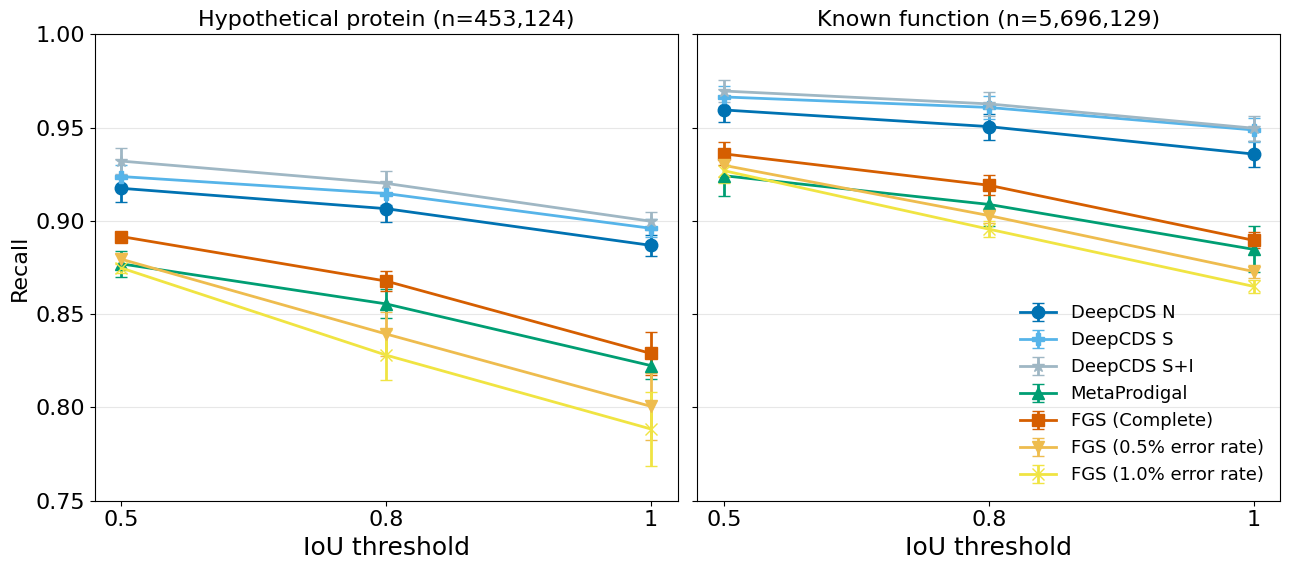

In [ ]:
import matplotlib.pyplot as plt
from plot_config import MODEL_COLORS, MODEL_MARKERS, FONT_SIZES
plt.rcParams.update(FONT_SIZES)

IOUS = [0.5, 0.8, 1.0]   # left to right: lenient -> exact match


def load_counts(iou):
    c = pd.read_csv(f"{RESULTS_DIR}/hypothetical_counts.tsv" if iou == 1.0
                    else f"{RESULTS_DIR}/hypothetical_counts_iou{iou:g}.tsv", sep="\t")
    if DOMAINS:
        c = c[c["domain"].isin(DOMAINS)]
    c = c[c["category"].isin(EVALUATED)]
    if EXCLUDE_OVERLAPPING_GENOMES:
        c = c[~c["genome_bin_id"].isin(_drop)]
    return c


rows = []
for iou in IOUS:
    c = load_counts(iou)
    for grp in EVALUATED:
        g = c[c["category"] == grp]
        rng = np.random.default_rng(SEED)
        for model in MODELS:
            per_bin = g[g["model"] == model].groupby("genome_bin_id")[["tp", "n"]].sum()
            per_bin = per_bin[per_bin["n"] > 0]
            tp, nn = per_bin["tp"].to_numpy(float), per_bin["n"].to_numpy(float)
            idx = rng.integers(0, len(tp), size=(N_BOOTSTRAP, len(tp)))
            rows.append({"iou": iou, "group": grp, "model": model, "recall": tp.sum() / nn.sum(),
                         "se": (tp[idx].sum(axis=1) / nn[idx].sum(axis=1)).std(ddof=1), "n": int(nn.sum())})
by_iou = pd.DataFrame(rows)
display(by_iou.assign(model=by_iou["model"].map(MODEL_DISPLAY_NAMES))
        .pivot_table(index="model", columns=["group", "iou"], values="recall").round(3)
        .reindex([MODEL_DISPLAY_NAMES[m] for m in MODELS]))
save(by_iou, "recall_by_iou")

LABEL_SIZE, TICK_SIZE, TITLE_SIZE, LEGEND_SIZE = 20, 18, 20, 16

fig, axes = plt.subplots(1, len(EVALUATED), figsize=(14, 7), sharey=True)
x = np.arange(len(IOUS))
for ax, grp in zip(axes, EVALUATED):
    sub = by_iou[by_iou["group"] == grp]
    for model in MODELS:
        m = sub[sub["model"] == model].set_index("iou").loc[IOUS]
        ax.errorbar(x, m["recall"], yerr=m["se"], color=MODEL_COLORS[model], marker=MODEL_MARKERS[model],
                    markersize=9, capsize=4, linewidth=2, label=MODEL_DISPLAY_NAMES[model])
    ax.set_title(f"{CATEGORY_LABELS[grp]} (n={sub['n'].iloc[0]:,})", fontsize=TITLE_SIZE)
    ax.set_xticks(x, [f"{i:g}" for i in IOUS])
    ax.tick_params(axis="both", labelsize=TICK_SIZE)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Sensitivity", fontsize=LABEL_SIZE)
axes[0].set_ylim(0.75, 1.0)
fig.supxlabel("IoU threshold", fontsize=LABEL_SIZE, y=0.165)   # one x-axis label shared by both panels
handles, labels = axes[0].get_legend_handles_labels()
LEGEND_ORDER = ["fgs_complete", "fgs_illumina_5", "fgs_illumina_10", "prodigal",
                "deep_cds_no_errors", "deep_cds_substitution", "deep_cds_errors"]   # same order as the other figures
by_label = dict(zip(labels, handles))
labels = [MODEL_DISPLAY_NAMES[m] for m in LEGEND_ORDER]
handles = [by_label[l] for l in labels]
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, fontsize=LEGEND_SIZE,
           bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.15, 1, 1))   # leave room below the panels for the label and legend
if SAVE_OUTPUTS:
    os.makedirs(f"{RESULTS_DIR}/figures", exist_ok=True)
    fig.savefig(f"{RESULTS_DIR}/figures/recall_by_iou.png", bbox_inches="tight", dpi=300)
plt.show()